BREAST CANCER DATASET
--------------------------------------------------
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dim

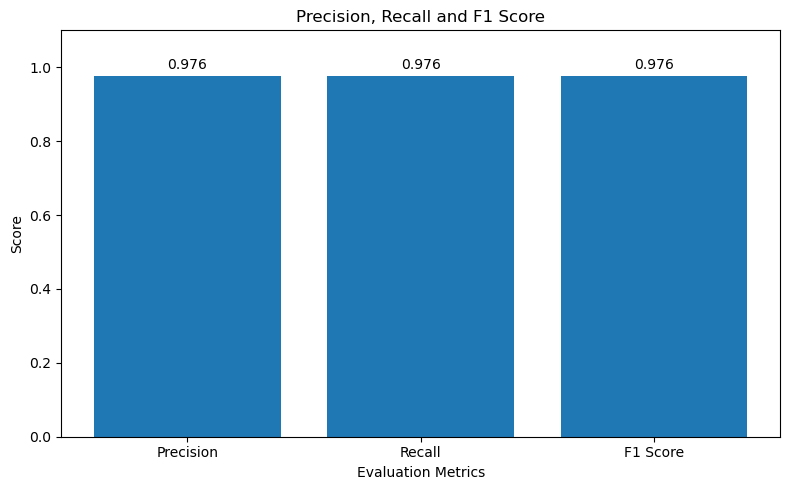

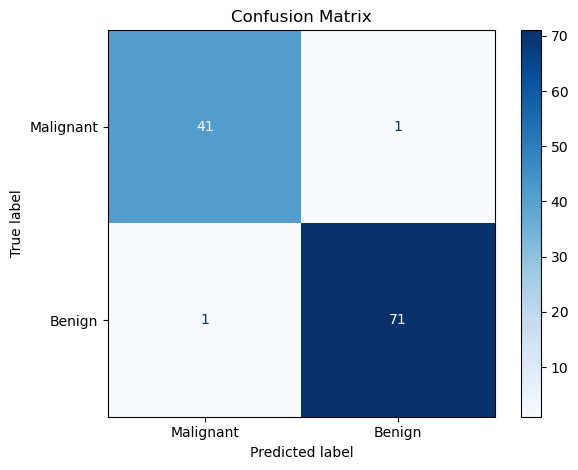


Evaluation completed successfully!
Saved Files:
1. classification_metrics.csv
2. performance_metrics.png
3. confusion_matrix.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


# ---------------------------------------------------------
# 1. Load Breast Cancer Dataset
# ---------------------------------------------------------

data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = data.target

print("BREAST CANCER DATASET")
print("-" * 50)

print(X.head())
print("\nDataset Shape:", X.shape)

print("\nTarget Classes:", data.target_names)


# ---------------------------------------------------------
# 2. Split the Dataset
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ---------------------------------------------------------
# 3. Create and Train Classification Model
# ---------------------------------------------------------

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)

model.fit(X_train, y_train)


# ---------------------------------------------------------
# 4. Make Predictions
# ---------------------------------------------------------

predictions = model.predict(X_test)


# ---------------------------------------------------------
# 5. Calculate Evaluation Metrics
# ---------------------------------------------------------

# Class 0 represents Malignant

precision = precision_score(
    y_test,
    predictions,
    pos_label=0
)

recall = recall_score(
    y_test,
    predictions,
    pos_label=0
)

f1 = f1_score(
    y_test,
    predictions,
    pos_label=0
)

print("\nMODEL PERFORMANCE")
print("-" * 50)

print("Precision Score:", round(precision, 4))
print("Recall Score   :", round(recall, 4))
print("F1 Score       :", round(f1, 4))


# ---------------------------------------------------------
# 6. Explain the Metrics
# ---------------------------------------------------------

print("\nMETRIC INTERPRETATION")
print("-" * 50)

print("Precision: Correct malignant predictions among")
print("           all predicted malignant cases.")

print("\nRecall: Actual malignant cases correctly identified.")

print("\nF1 Score: Harmonic mean of Precision and Recall.")


# ---------------------------------------------------------
# 7. Display Classification Report
# ---------------------------------------------------------

print("\nCLASSIFICATION REPORT")
print("-" * 50)

print(
    classification_report(
        y_test,
        predictions,
        target_names=data.target_names
    )
)


# ---------------------------------------------------------
# 8. Graphical Output - Performance Metrics
# ---------------------------------------------------------

metrics = ["Precision", "Recall", "F1 Score"]

scores = [precision, recall, f1]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics,
    scores
)

plt.title("Precision, Recall and F1 Score")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.1)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("performance_metrics.png")
plt.show()


# ---------------------------------------------------------
# 9. Confusion Matrix
# ---------------------------------------------------------

cm = confusion_matrix(
    y_test,
    predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

display.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()
